<a href="https://colab.research.google.com/github/dahae0515/Baseline_Models/blob/main/point_space_new_features_5S.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Point detection on ROSpace 5S

## Import Dataset

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
time_bin = '5S'

In [ ]:
df = pd.read_csv('../data/datasets/rospace/aggregated/merged/rospace_merged_time5S.csv')
#df = df.rename(columns={'attack': 'label'})

/tmp/ipykernel_6675/687904581.py:1: DtypeWarning: Columns (4,6,8,9,10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/datasets/rospace/aggregated/merged/rospace_merged_time5S.csv')


In [ ]:
print(df.shape)

(10081647, 62)


In [ ]:
df = df.drop(columns=['Unnamed: 0'])

In [ ]:
df = df.drop('time5S', axis=1)
df = df.drop('time10S', axis=1)
df = df.drop('time30S', axis=1)
df = df.drop('time1min', axis=1)
df = df.drop('time5min', axis=1)
df = df.drop('time10min', axis=1)
df = df.drop('time30min', axis=1)
df = df.drop('time60min', axis=1)

In [ ]:
object_columns = [col for col in df.columns if df[col].dtype == 'object']
print(object_columns)

['layers.sll.sll.unused', 'layers.ip.ip.flags', 'layers.ip.ip.checksum', 'layers.tcp.tcp.flags_tree.tcp.flags.syn_tree._ws.expert._ws.expert.message', 'layers.tcp.tcp.options', 'layers.tcp.tcp.payload', 'layers._ws.short', 'src_topic', 'msg_type', 'msg_data', 'timestamp']


## Prepare the data for ML
In this section, we prepare the data to be processed by ML algorithms. In particular, we perform the following steps:

### Convert Label columns to Numeric values
We substitute label values with numeric binary values.

In [ ]:
print(df['label'])

0           0
1           0
2           0
3           0
4           0
           ..
10081642    1
10081643    1
10081644    1
10081645    1
10081646    1
Name: label, Length: 10081647, dtype: int64


In [ ]:
#df['label'].to_csv('./data/space/split_4/labels/multi_err_label.csv')

In [ ]:
print(df['label'].value_counts())

1    7867641
0    2214006
Name: label, dtype: int64


In [ ]:
root = '../data/datasets/rospace/'
multi_err_label = pd.read_csv(root + "multi_err_label.csv")

In [ ]:
multi_err_label['label'] = multi_err_label['label'].replace('metasploit SYN flood', 1)
multi_err_label['label'] = multi_err_label['label'].replace('nmap discovery', 2)
multi_err_label['label'] = multi_err_label['label'].replace('nmap SYN flood', 3)
multi_err_label['label'] = multi_err_label['label'].replace('ros2 node crashing', 4)
multi_err_label['label'] = multi_err_label['label'].replace('ros2 reconnaissance', 5)
multi_err_label['label'] = multi_err_label['label'].replace('ros2 reflection', 6)
multi_err_label['label'] = multi_err_label['label'].replace('observe', 0)

multi_err_label['label'] = pd.to_numeric(multi_err_label['label'])

multi_err_label['label'].unique(), multi_err_label['label'].nunique()

(array([0, 2, 5, 6, 4, 3, 1]), 7)

In [ ]:
df['timestamp'] = pd.to_datetime(df['timestamp'],
               format='%Y-%m-%d %H:%M:%S.%f')

In [ ]:
cat_cols = df.select_dtypes(include=['object', 'category']).columns
print(cat_cols)

Index(['layers.sll.sll.unused', 'layers.ip.ip.flags', 'layers.ip.ip.checksum',
       'layers.tcp.tcp.flags_tree.tcp.flags.syn_tree._ws.expert._ws.expert.message',
       'layers.tcp.tcp.options', 'layers.tcp.tcp.payload', 'layers._ws.short',
       'src_topic', 'msg_type', 'msg_data'],
      dtype='object')


### Convert String to Numeric

In [ ]:
list_column_string=df.select_dtypes(exclude=[np.number])

for i in list_column_string:
    if i != 'timestamp':
        df[i] = pd.Categorical(df[i])

In [ ]:
for i in list_column_string:
    if i != 'timestamp':
        df[i] = df[i].cat.codes

In [ ]:
df = df.replace([np.inf, -np.inf], np.nan)
df = df.replace([np.inf, -np.inf], np.nan)
df = df.fillna(0)
df = df.fillna(0)

## Load Train / Val / Test split indexes
The validation, train and test set lists contains list of indexes which are composed based on the original dataframe and are shuffled to define Train / Val / Test sets. Each lists indicates the indexes of a data point sequence (normal / attack concatenated) of the original dataframe. This way we can keep track of the data point info after blocks shuffle (such as multi class label and timestamp) just by qurying the original dataframe using sequence indexes.

In [ ]:
import numpy as np

In [ ]:
root = '../data/datasets/rospace/'

In [ ]:
validation_set_lists = np.load(root + 'rospace_val_lists_4.npy', allow_pickle=True)

In [ ]:
train_set_lists = np.load(root + 'rospace_train_lists_4.npy', allow_pickle=True)

In [ ]:
test_set_lists = np.load(root + 'rospace_test_lists_4.npy', allow_pickle=True)

## Convert the Pandas Dataframe to numpy

In [ ]:
Y=df['label'].to_numpy()

In [ ]:
df = df.drop('label', axis=1)

In [ ]:
print(df['timestamp'].dtype)

datetime64[ns]


In [ ]:
timestamp = df['timestamp'].to_numpy()

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
print(timestamp)

['2023-03-16T14:22:23.903192576' '2023-03-16T14:22:23.904744448'
 '2023-03-16T14:22:23.905824512' ... '2023-06-16T19:57:32.405588992'
 '2023-06-16T19:57:32.406351616' '2023-06-16T19:57:32.406712064']


In [ ]:
df = df.drop('timestamp', axis=1)

In [ ]:
X=df.to_numpy()

In [ ]:
print(Y.shape)
print(X.shape)

(10081647,)
(10081647, 51)


In [ ]:
# Save the multiclass label in numpy format
multi_err_label = multi_err_label['label'].to_numpy()

## Form the Train / Val / Test split by using sequence idexes

In [ ]:
train_x = np.concatenate([X[idx] for idx in train_set_lists])
train_y = np.concatenate([Y[idx] for idx in train_set_lists])
train_lab = np.concatenate([multi_err_label[idx] for idx in train_set_lists])
train_time = np.concatenate([timestamp[idx] for idx in train_set_lists])

val_x = np.concatenate([X[idx] for idx in validation_set_lists])
val_y = np.concatenate([Y[idx] for idx in validation_set_lists])
val_lab = np.concatenate([multi_err_label[idx] for idx in validation_set_lists])
val_time = np.concatenate([timestamp[idx] for idx in validation_set_lists])

test_x = np.concatenate([X[idx] for idx in test_set_lists])
test_y = np.concatenate([Y[idx] for idx in test_set_lists])
test_lab = np.concatenate([multi_err_label[idx] for idx in test_set_lists])
test_time = np.concatenate([timestamp[idx] for idx in test_set_lists])

# Print the resulting train, validation, and test sets
print("Train Set (X):\n", train_x)
print("\nTrain Set (Y):\n", train_y)
print("\nTrain Set (err):\n", train_lab)
print("\nTrain Set (Timestamps):\n", train_time)

print("Train Set (X):\n", train_x.shape)
print("\nTrain Set (Y):\n", train_y.shape)
print("\nTrain Set (err):\n", train_lab.shape)
print("\nTrain Set (Timestamps):\n", train_time.shape)

print("\nValidation Set (X):\n", val_x)
print("\nValidation Set (Y):\n", val_y)
print("\nValidation Set (err):\n", val_lab)
print("\nValidation Set (Timestamps):\n", val_time)

print("\nTest Set (X):\n", test_x)
print("\nTest Set (Y):\n", test_y)
print("\nTest Set (err):\n", test_lab)
print("\nTest Set (Timestamps):\n", test_time)

Train Set (X):
 [[ 4.73840000e+04  1.90000000e+01  3.99460000e+04 ... -3.93364929e-01
   8.49289100e-01  2.87170578e-03]
 [ 9.46600000e+03  1.90000000e+01  3.99910000e+04 ... -3.93364929e-01
   8.49289100e-01  2.87170578e-03]
 [ 3.61590000e+04  1.90000000e+01  3.84320000e+04 ... -3.93364929e-01
   8.49289100e-01  2.87170578e-03]
 ...
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  6.26836759e+00
   1.06997150e+02 -3.72023224e-04]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  6.26836759e+00
   1.06997150e+02 -3.72023224e-04]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  6.26836759e+00
   1.06997150e+02 -3.72023224e-04]]

Train Set (Y):
 [0 0 0 ... 1 1 1]

Train Set (err):
 [0 0 0 ... 3 3 3]

Train Set (Timestamps):
 ['2023-06-12T14:29:03.433616384' '2023-06-12T14:29:03.433960448'
 '2023-06-12T14:29:03.434494720' ... '2023-06-15T15:40:31.983340544'
 '2023-06-15T15:40:31.983961600' '2023-06-15T15:40:31.983961600']
Train Set (X):
 (5439177, 51)

Train Set (Y):
 (54

## Run detectors
Each cell group is dedicated to one of the models selected for the paper. To have results execute the cells to get predictions and run:
1) Evaluate block detection performances: to compute latency results with a fixed FPR. Output will not be saved.
2) Loop FPR Evaluation: to compute latency results using different FPR thresholds. Output is saved for further processing.

## XGBoost

### Train XGBoost

In [ ]:
from xgboost import XGBClassifier

In [ ]:
bst = XGBClassifier(n_estimators=10, max_depth=20, learning_rate=1.0, objective='binary:logistic')

In [ ]:
bst.fit(train_x, train_y)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=1.0, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=20, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=10, n_jobs=None, num_parallel_tree=None,
              predictor=None, random_state=None, ...)

In [ ]:
bst.save_model('../data/models/space/new_features/xgb/' + time_bin + '/xgb.h5')

In [ ]:
bst.load_model('../data/models/space/new_features/xgb/' + time_bin + '/xgb.h5')

### Test XGBoost

In [ ]:
import sklearn
from sklearn import metrics
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
import numpy as np

In [ ]:
preds = bst.predict(test_x)

In [ ]:
preds_proba=bst.predict_proba(test_x)

In [ ]:
np.save('../data/models/space/new_features/xgb/' + time_bin + '/preds_proba', preds_proba)

In [ ]:
preds_proba = np.load('../data/models/space/new_features/xgb/' + time_bin + '/preds_proba.npy')

In [ ]:
test_y = np.load('../data/datasets/rospace/test_y.npy')

In [ ]:
fpr, tpr, thresholds = metrics.roc_curve(test_y, preds_proba[:,1])
desired_fpr = 0.01
index = np.argmax(fpr > desired_fpr)
threshold_fpr = thresholds[index]
bin_pred = (preds_proba[:, 1] > threshold_fpr).astype(int)
acc=sklearn.metrics.accuracy_score(test_y, bin_pred)
recall=sklearn.metrics.recall_score(test_y, bin_pred)
f1=sklearn.metrics.f1_score(test_y, bin_pred)
tn, fp, fn, tp = sklearn.metrics.confusion_matrix(test_y, bin_pred).ravel()
print("usual accuracy and confusion matrix tn, fp, fn, tp")
acc, recall, f1, tn, fp, fn, tp

usual accuracy and confusion matrix tn, fp, fn, tp


(0.8212730326012359,
 0.7790927578089597,
 0.8746061866853748,
 684235,
 6892,
 610822,
 2154239)

### XGBoost: Evaluate Overall data point classification performances

In [ ]:
import sklearn
from sklearn import metrics

In [ ]:
acc=sklearn.metrics.accuracy_score(test_y, preds)
tn, fp, fn, tp = sklearn.metrics.confusion_matrix(test_y, preds).ravel()
print("usual accuracy and confusion matrix tn, fp, fn, tp")
acc, tn, fp, fn, tp

usual accuracy and confusion matrix tn, fp, fn, tp


(0.909401340436342, 597516, 93611, 219515, 2545546)

In [ ]:
fposr = fp / (tp + fp)
print(fposr)

0.035470038349366864


In [ ]:
fpr, tpr, _ = metrics.roc_curve(test_y,  preds_proba[:,1])

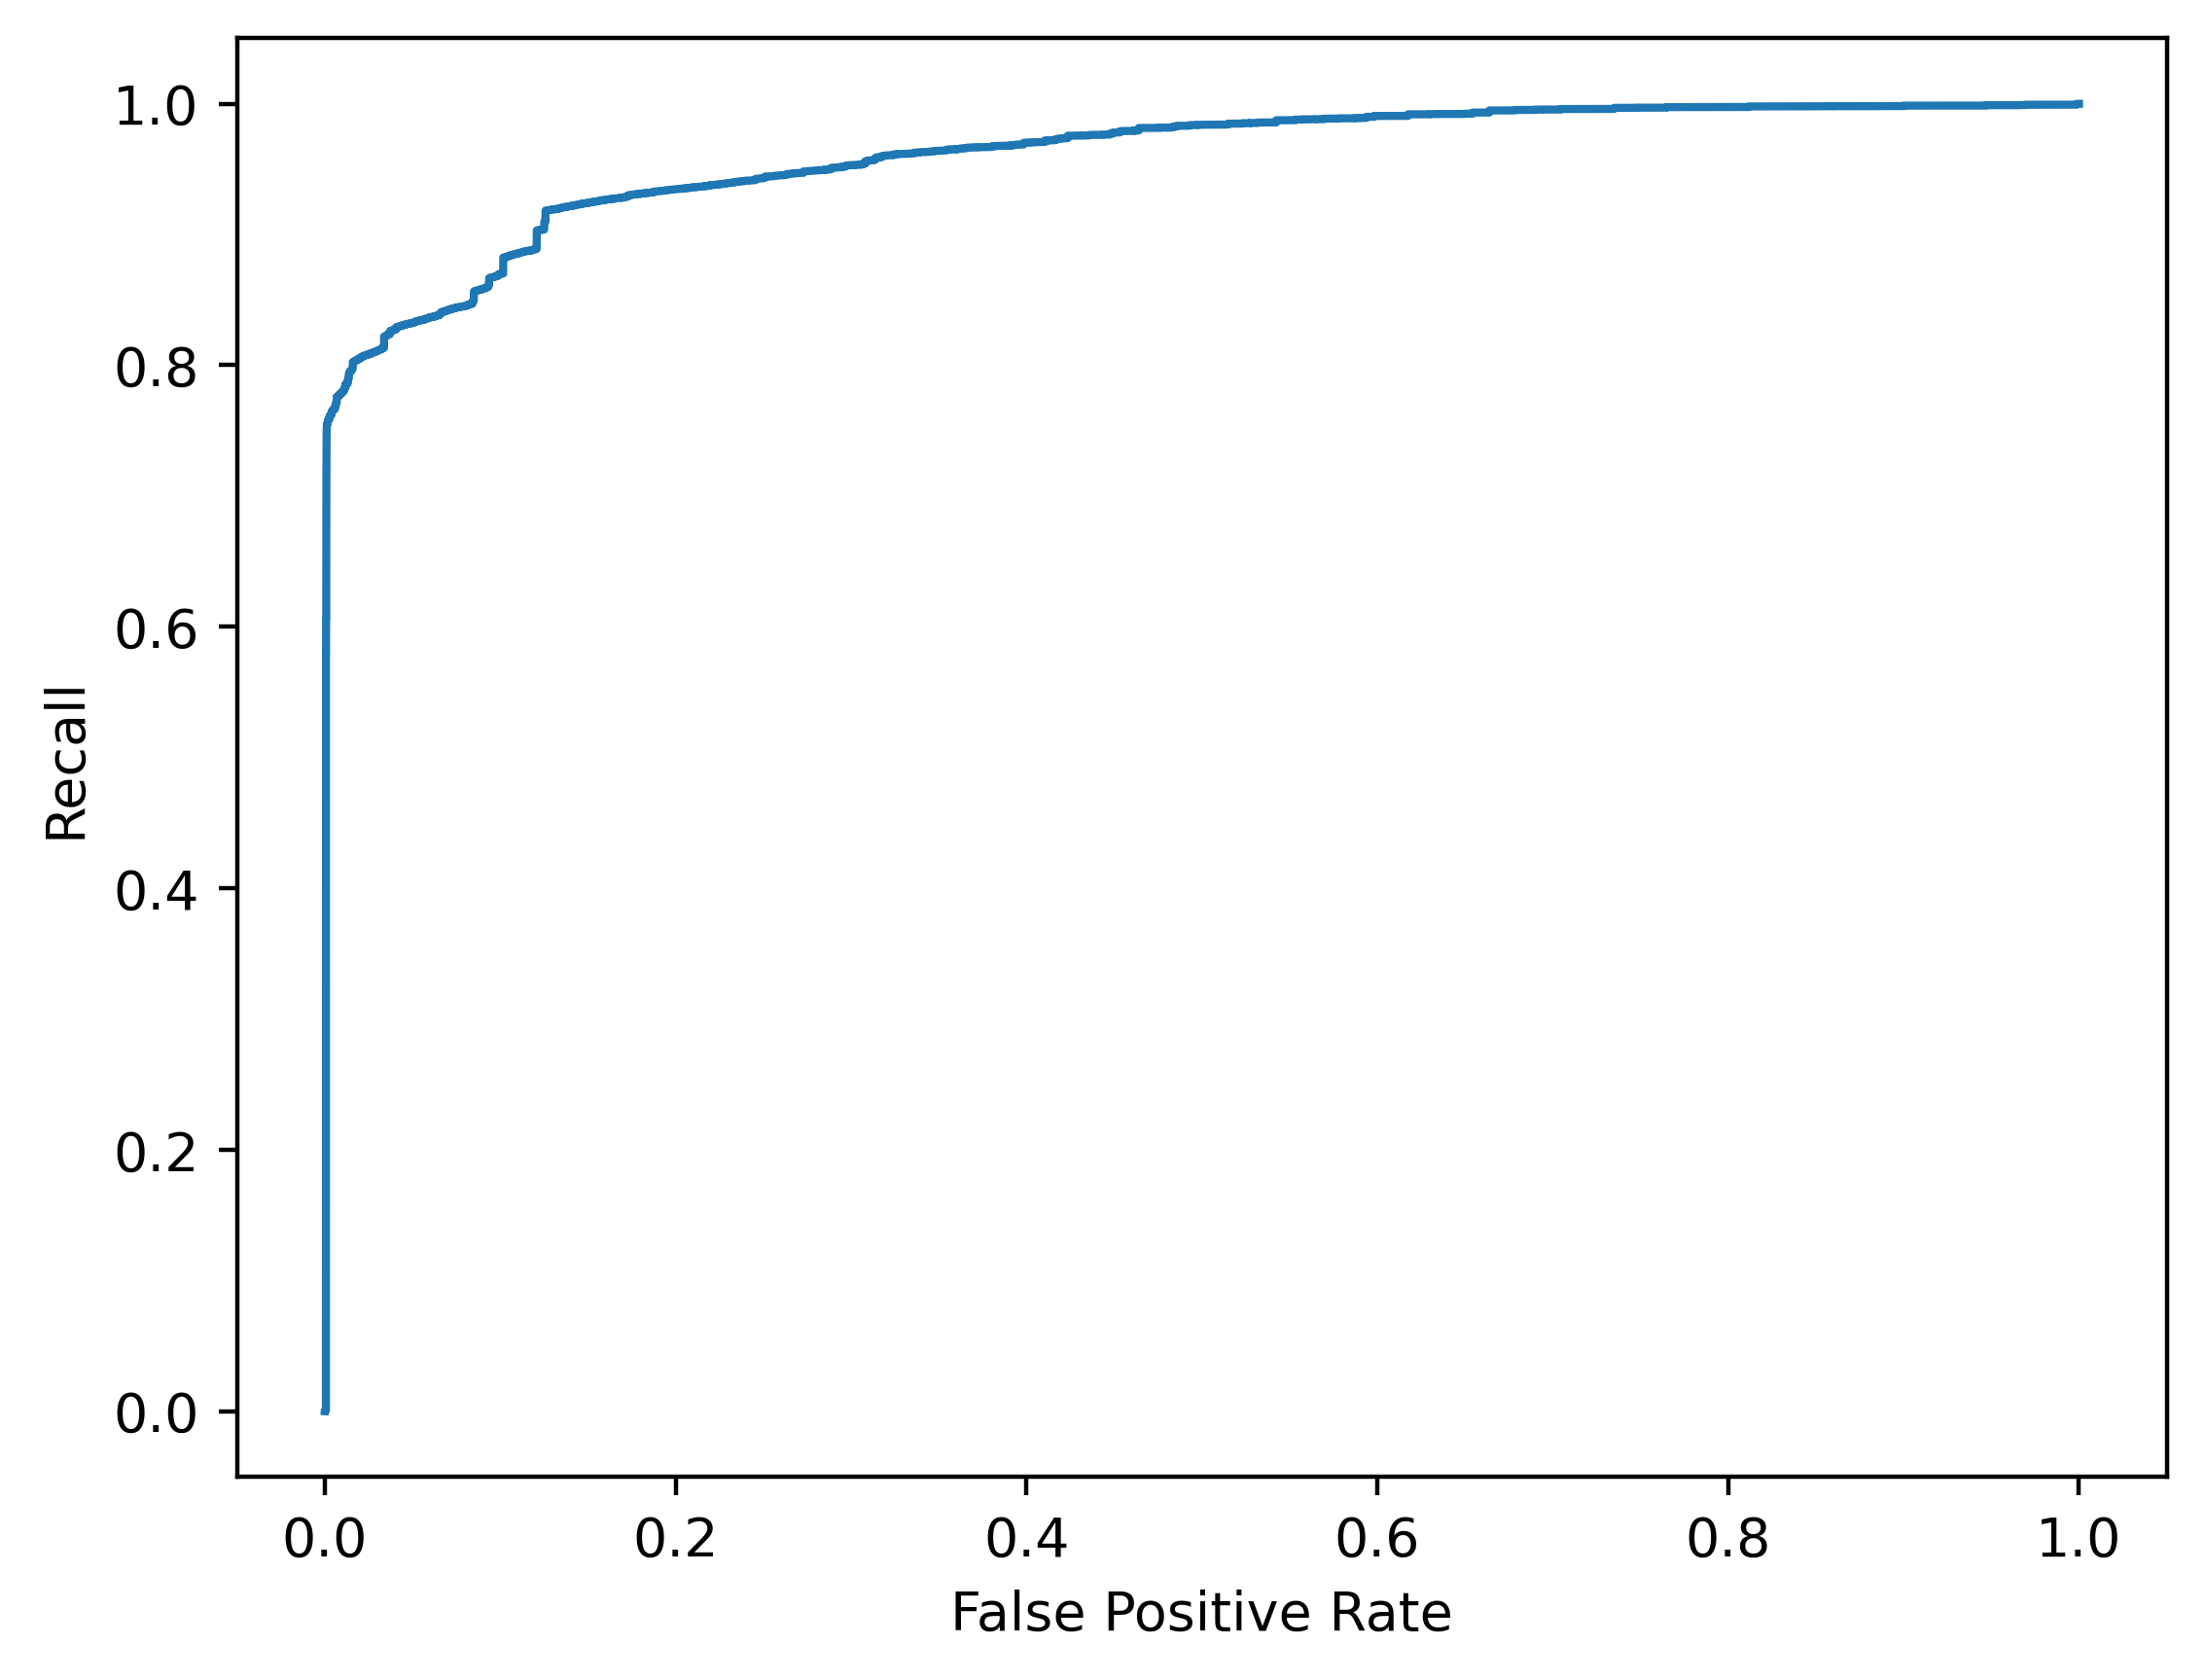

In [ ]:
plt.figure(dpi=400)

plt.plot(fpr, tpr)
plt.ylabel('Recall')
plt.xlabel('False Positive Rate')
plt.show()

In [ ]:
pr = sklearn.metrics.precision_score(test_y, preds)
rec = sklearn.metrics.recall_score(test_y, preds)
print(pr, rec)

0.9645299616506331 0.9206111546906198


In [ ]:
precision, recall, thr = metrics.precision_recall_curve(test_y,  preds_proba[:,1])

In [ ]:
filtered_recall = [r for r in recall if r > 0.50]
filtered_precision = [precision[i] for i, r in enumerate(recall) if r > 0.50]

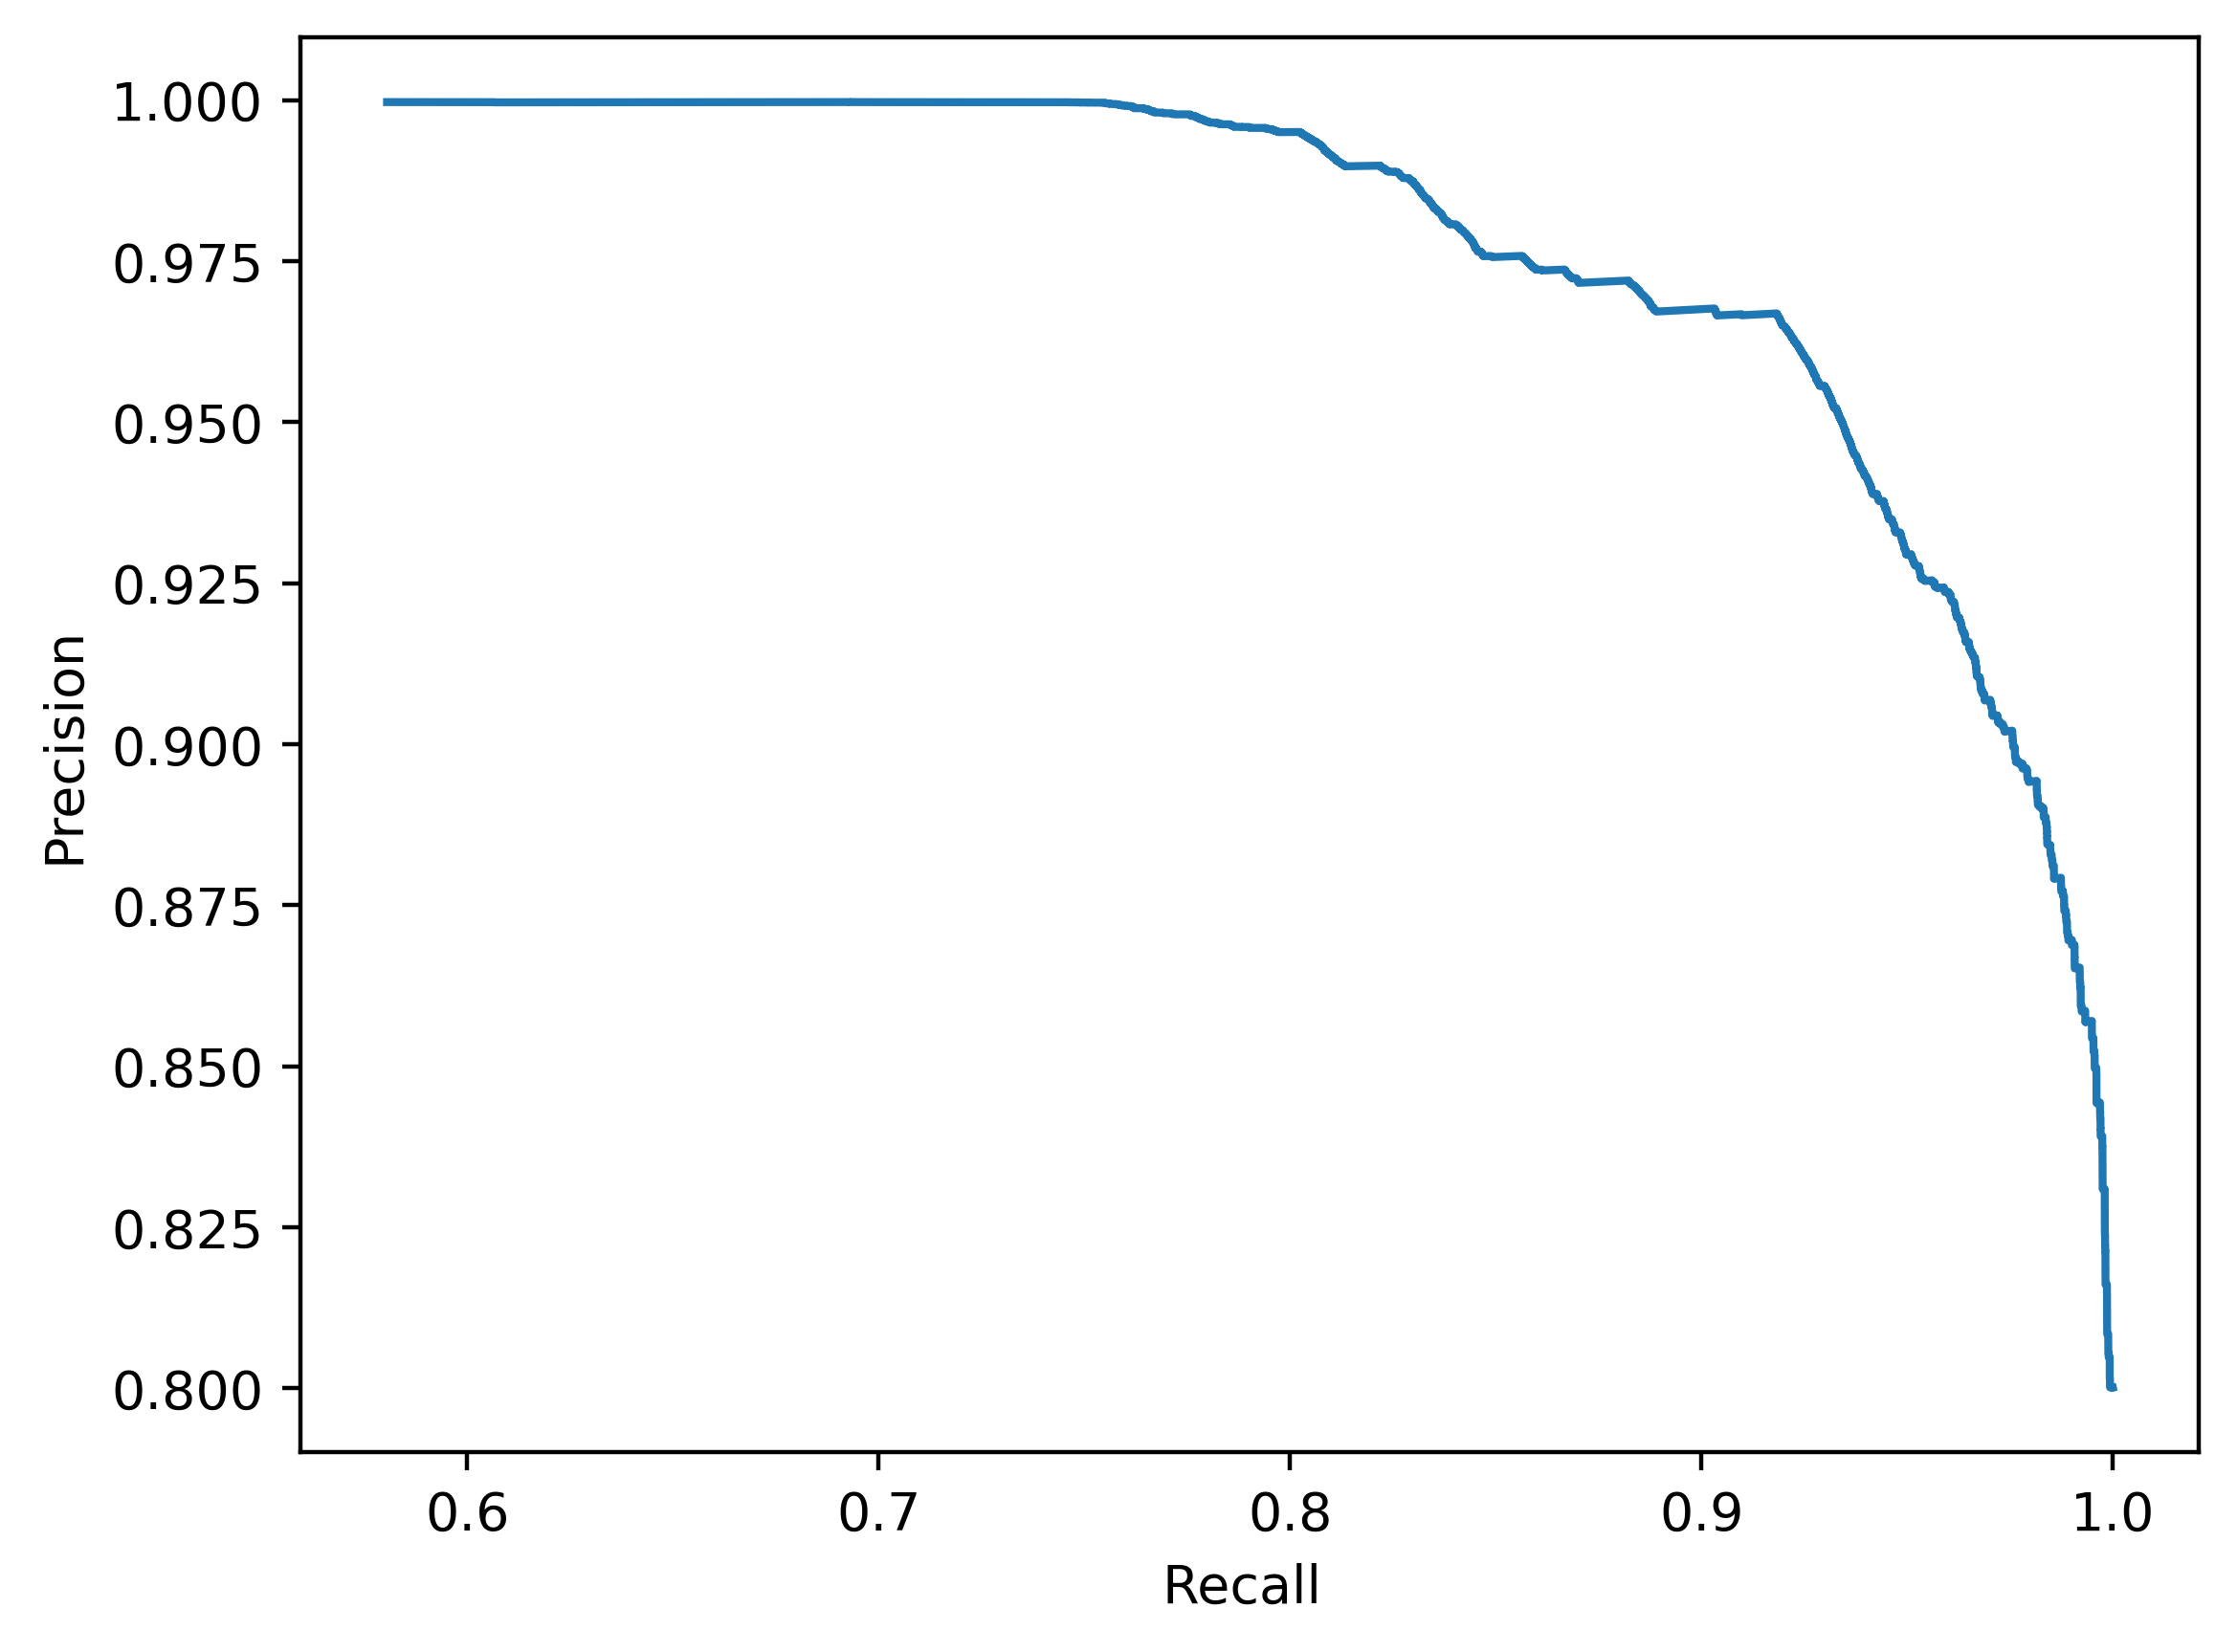

In [ ]:
plt.figure(dpi=400)
plt.plot(filtered_recall, filtered_precision)
plt.ylabel('Precision')
plt.xlabel('Recall ')
plt.show()

### Latency / FPR evaluation loop

In [ ]:
import os
import pandas as pd
import numpy as np
import sklearn
from sklearn import metrics
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
from sklearn.metrics import roc_curve
from sklearn.metrics import precision_recall_curve

In [ ]:
fpr, tpr, thresholds = metrics.roc_curve(test_y, preds_proba[:,1])
desired_fpr = [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]

In [ ]:
fpr_indexes = []
for val in desired_fpr:
    index = np.argmax(fpr > val)
    fpr_indexes.append(index)

In [ ]:
fpr_thresholds = thresholds[fpr_indexes]

In [ ]:
bin_preds_fpr = []
for val in fpr_thresholds:
    bin_pred = (preds_proba > val).astype(int)[:, 1]
    bin_preds_fpr.append(bin_pred)

In [ ]:
bin_preds_fpr

[array([0, 0, 0, ..., 0, 0, 0]),
 array([0, 0, 0, ..., 0, 0, 0]),
 array([0, 0, 0, ..., 0, 0, 0]),
 array([0, 0, 0, ..., 0, 0, 0]),
 array([0, 0, 0, ..., 0, 0, 0]),
 array([0, 0, 0, ..., 1, 1, 1]),
 array([0, 0, 0, ..., 1, 1, 1])]

In [ ]:
from dateutil.parser import parse

for val, des_fpr in zip(bin_preds_fpr, desired_fpr):
    bin_pred = val

    df_out = pd.DataFrame(columns=['start_idx_attack', 'end_idx_attack', 'attack_duration', 'time_to_detect', 'idx_detection_abs', 'idx_detection_rel', 'attack_len', 'attack_type','fpr','tpr','pr','rec','tn', 'fp','fn','tp','target_fpr'])
    last = 0
    i = 0
    for seq in test_set_lists:
        seq_x = X[seq]
        seq_y = Y[seq]
        seq_preds = bin_pred[last: last + seq_y.shape[0]]
        seq_preds = np.array(seq_preds)

        seq_check = test_y[last: last + seq_y.shape[0]]
        y_test_atk= np.where(Y[seq] == 1)[0]
        y_test_norm= np.where(Y[seq] ==  0)[0]

        conf_matrix = sklearn.metrics.confusion_matrix(seq_y, seq_preds)
        tn, fp, fn, tp = conf_matrix.ravel()
        fpr = fp / (tp + fp)
        tpr = tp / (tp + fn)

        pr = sklearn.metrics.precision_score(seq_y, seq_preds)
        rec = sklearn.metrics.recall_score(seq_y, seq_preds)

        preds_1=seq_preds[y_test_atk]

        date_time_0 = timestamp[seq[y_test_atk[0]]]
        date_time_last = timestamp[seq[y_test_atk[len(y_test_atk)-1]]]
        attack_time = date_time_last - date_time_0

        if 1 in seq_preds[y_test_atk]:
            index_rel = np.where(seq_preds[y_test_atk] == 1)[0][0]
            index = seq[y_test_atk[index_rel]]

            date_time_index = timestamp[index]
            detection_time = date_time_index - date_time_0
        else:
            index_rel = -1
            index = -1
            detection_time = -1

        df_out.loc[i] = pd.Series({'start_idx_attack': seq[y_test_atk[0]], 'end_idx_attack': seq[y_test_atk[len(y_test_atk)-1]],
                               'attack_duration': attack_time , 'time_to_detect': detection_time, 'idx_detection_abs': index,
                               'idx_detection_rel':index_rel, 'attack_len': y_test_atk.shape[0],
                               'attack_type':multi_err_label[seq[y_test_atk[0]]],'fpr':fpr,'tpr': tpr, 'pr': pr, 'rec': rec,
                               'tn':tn, 'fp':fp, 'fn':fn, 'tp':tp, 'target_fpr':des_fpr})
        last = last+len(seq_y)
        i = i+1
    print(des_fpr)
    path = '../data/models/space/new_features/xgb/' + time_bin + '/' + str(des_fpr) + '.csv'
    df_out.to_csv(path, index=None)

/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp 

0.0001


/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp 

0.0005


/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp 

0.001


... (4 outputs left out)

/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp 

0.05


/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/3605435058.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp 

0.1


In [ ]:
#### Adjust Latency to consider sequence duration as leght when not detected

In [ ]:
root = '../data/models/space/new_features/xgb/' + time_bin + '/'

In [ ]:
files = os.listdir(root)
csv_files = [file for file in files if file.endswith('.csv')]

In [ ]:
csv_files

['0.1.csv',
 '0.0001.csv',
 '0.001.csv',
 '0.01.csv',
 '0.05.csv',
 '0.005.csv',
 '0.0005.csv']

In [ ]:
for csv in csv_files:

    path = root + csv
    df = pd.read_csv(path)
    df['detected'] = df['idx_detection_abs'].apply(lambda x: 0 if x == -1 else 1)
    df.loc[df['detected'] == 0, 'idx_detection_rel'] = df['attack_len'] - 1
    df.loc[df['detected'] == 0, 'time_to_detect'] = df['attack_duration']
    df.loc[df['detected'] == 0, 'idx_detection_abs'] = df['end_idx_attack']
    df.to_csv(path[0:len(path)-4] + '_new.csv' , index=None)


In [ ]:
c

## Isolation Forest

### Train Isolation Forest

In [ ]:
from sklearn.ensemble import IsolationForest as isol
import sklearn
import matplotlib.pyplot as plt

If data points shuffle needed

In [ ]:
num_samples = train_x.shape[0]
permutation = np.random.permutation(num_samples)
shuffled_train_x = train_x[permutation, :]
shuffled_train_y = train_y[permutation]

In [ ]:
#contamination=1-(np.sum(shuffled_train_y)/np.shape(shuffled_train_y))
is_forsest = isol(n_estimators=300, contamination=0.25)
# fit model
is_forsest.fit(train_x)

IsolationForest(contamination=0.25, n_estimators=300)

In [ ]:
import joblib

In [ ]:
joblib.dump(is_forsest, './data/space/split_4/model/isol_space_down0.3.h5')

In [ ]:
is_forsest = joblib.load('./data/space/split_4/model/isol_space_down0.3.h5')

### Test Isolation Forest

In [ ]:
import sklearn
from sklearn import metrics
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

In [ ]:
# make predictions
preds = is_forsest.predict(test_x)

In [ ]:
preds_proba = is_forsest.decision_function(test_x)

In [ ]:
preds[preds==1]=0
preds[preds==-1]=1
contamination

In [ ]:
#np.save(root + 'preds/prediction_probabilities_isol_space_cont25_4', preds_proba)

In [ ]:
preds_proba = np.load(root + 'preds/prediction_probabilities_isol_space_4.npy')

### Isolation Forests: Evaluate Overall data point classification performances

In [ ]:
import sklearn
from sklearn import metrics

In [ ]:
acc=sklearn.metrics.accuracy_score(test_y, preds)
tn, fp, fn, tp = sklearn.metrics.confusion_matrix(test_y, preds).ravel()
print("usual accuracy and confusion matrix tn, fp, fn, tp")
acc, tn, fp, fn, tp

In [ ]:
fposr = fp / (tp + fp)
print(fposr)

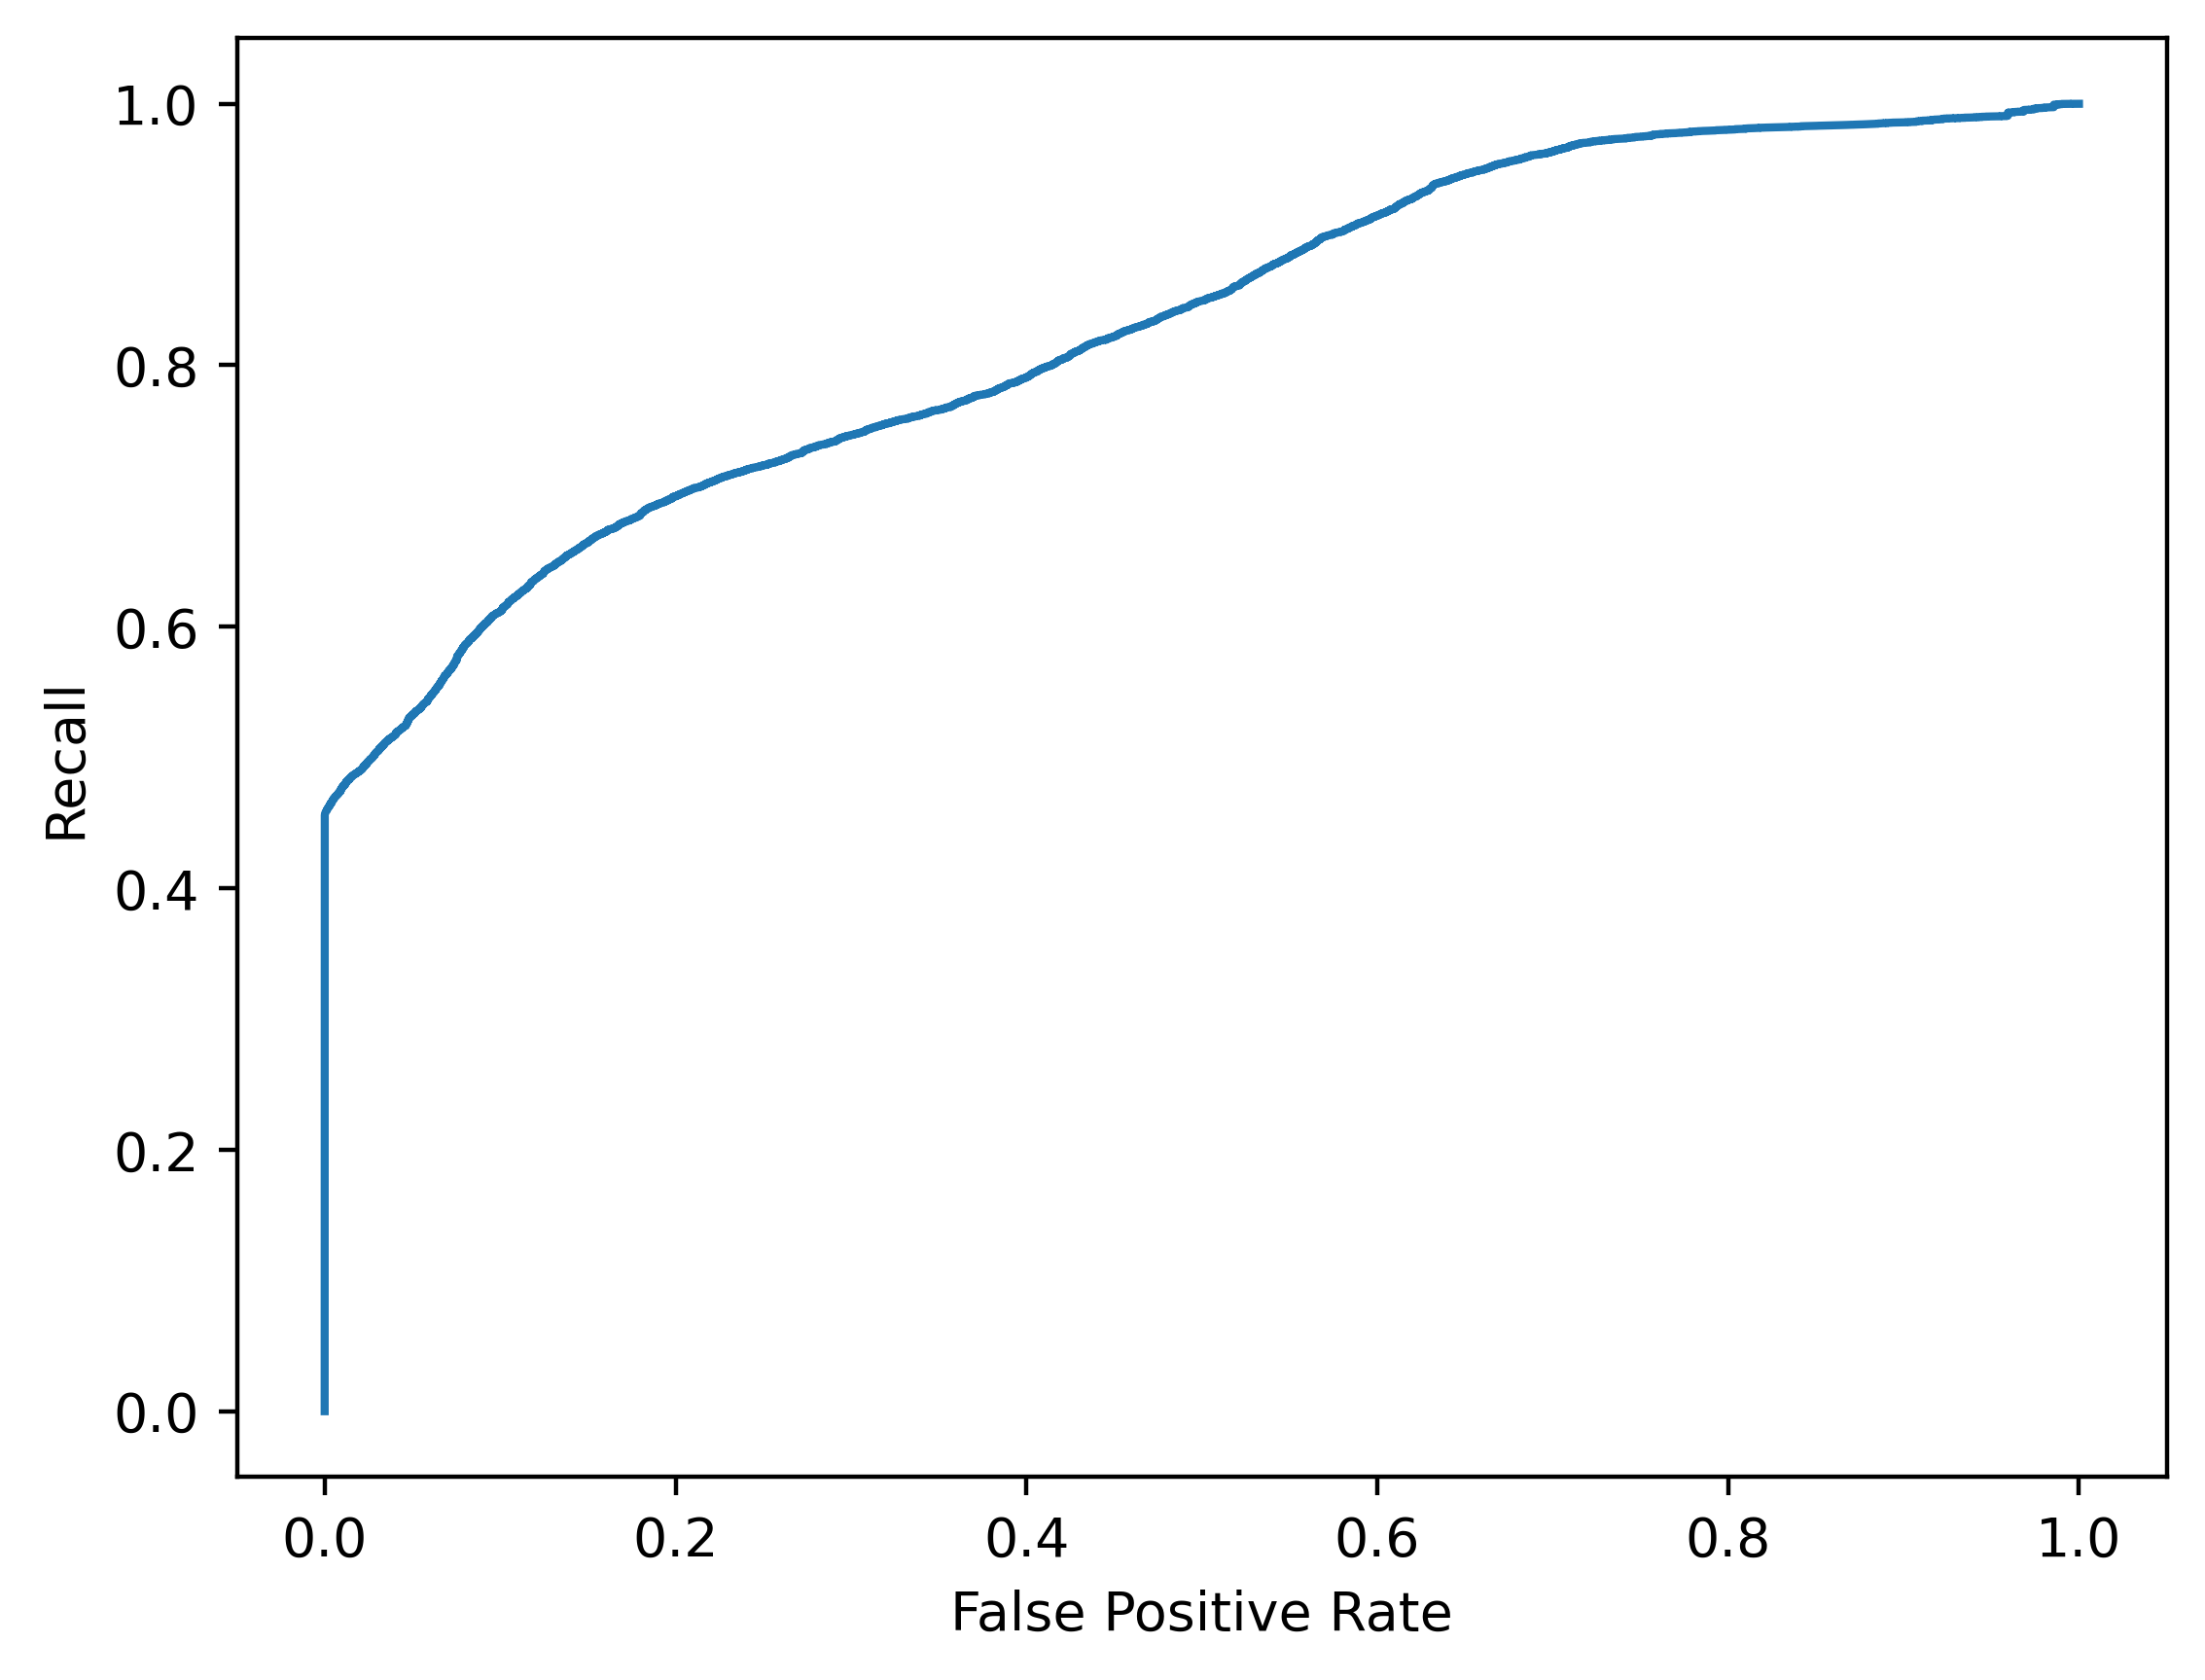

In [ ]:
plt.figure(dpi=400)
fpr, tpr, _ = metrics.roc_curve(test_y,  preds_proba)
plt.plot(fpr,tpr)
plt.ylabel('Recall')
plt.xlabel('False Positive Rate')
plt.show()

In [ ]:
pr = sklearn.metrics.precision_score(test_y, preds)
rec = sklearn.metrics.recall_score(test_y, preds)
print(pr, rec)

In [ ]:
precision, recall, thr = metrics.precision_recall_curve(test_y,  preds_proba)

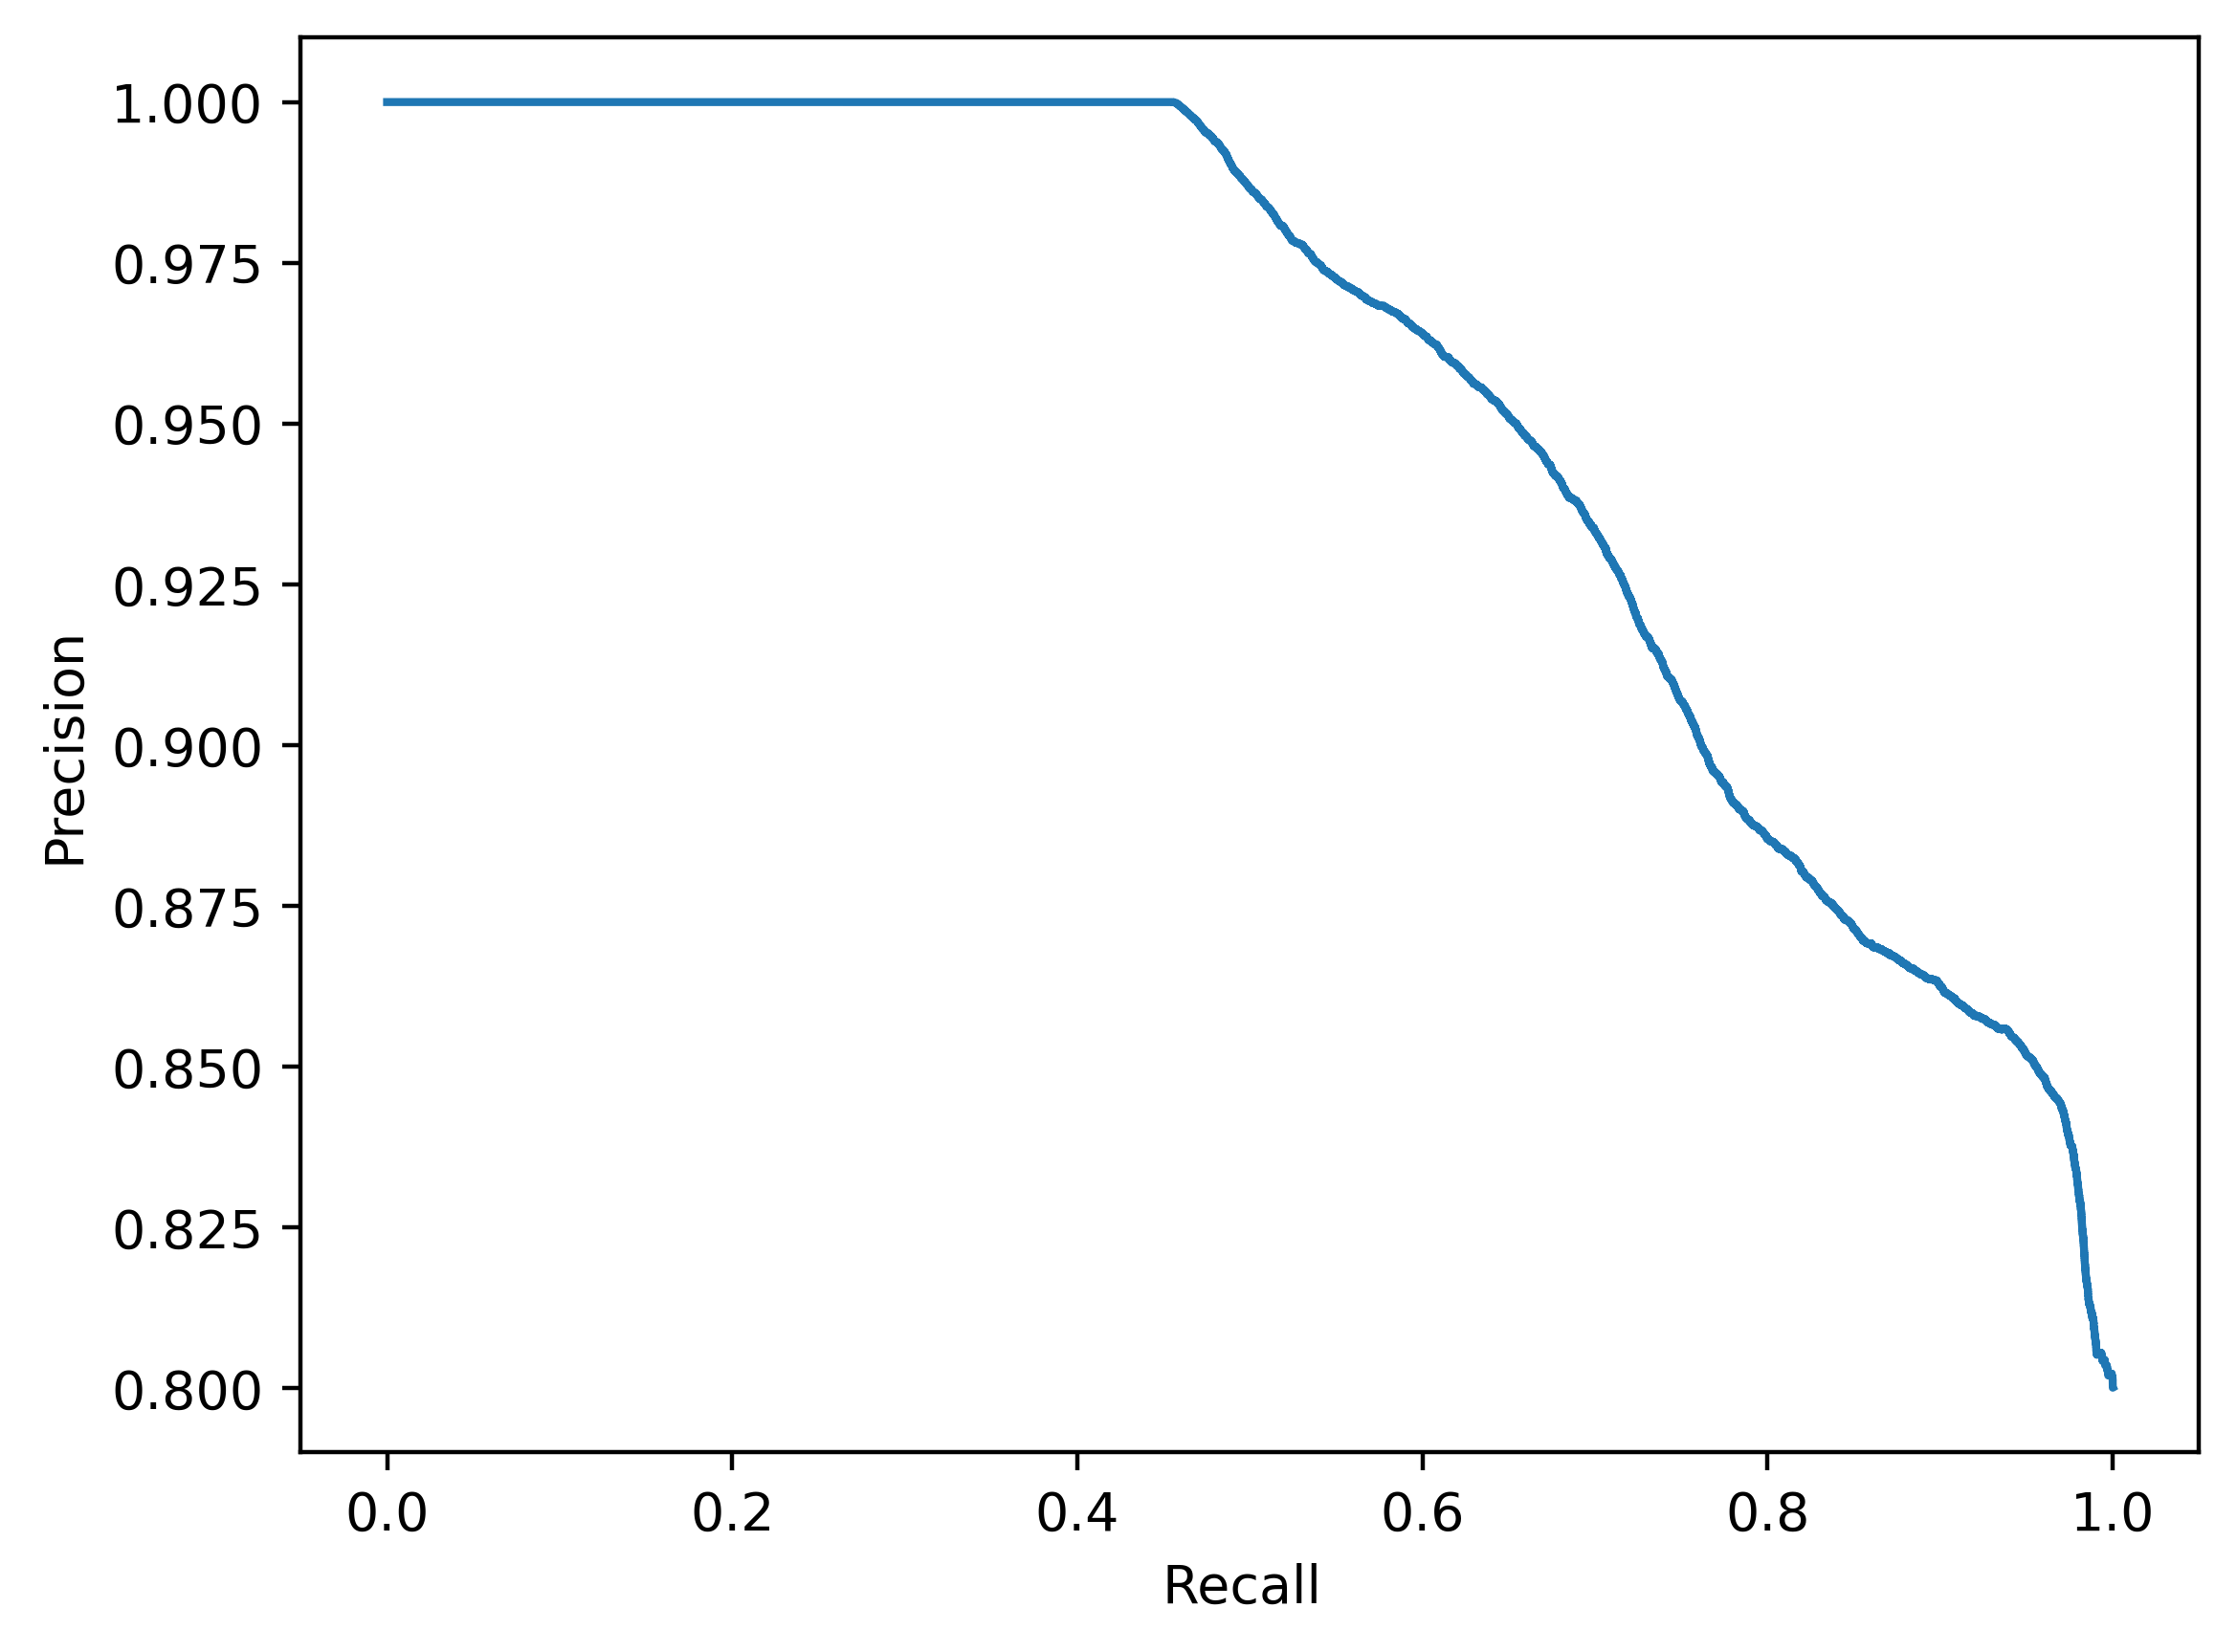

In [ ]:
plt.figure(dpi=400)
plt.plot(recall, precision)
plt.ylabel('Precision')
plt.xlabel('Recall ')
plt.show()

## Random Forest ExtraTreeClassifier

### Train ExtraTreeClassifier

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

In [ ]:
clf = ExtraTreesClassifier(n_estimators=100, random_state=0)

In [ ]:
clf.fit(train_x, train_y)

ExtraTreesClassifier(random_state=0)

In [ ]:
import joblib
joblib.dump(clf, '../data/models/space/new_features/extra/' + time_bin + '/extra.h5')

['../data/models/space/new_features/extra/5S/extra.h5']

In [ ]:
clf = joblib.load('../data/models/space/new_features/extra/' + time_bin + '/extra.h5')

### Test ExtraTreeClassifier

In [ ]:
import sklearn
from sklearn import metrics
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

In [ ]:
preds = clf.predict(test_x)

In [ ]:
preds_proba = clf.predict_proba(test_x)

In [ ]:
np.save('../data/models/space/new_features/extra/' + time_bin + '/preds_proba', preds_proba)
np.save('../data/models/space/new_features/extra/' + time_bin + '/preds', preds)

### ExtraTreeClassifier: Evaluate Overall data point classification performances

In [ ]:
import sklearn
from sklearn import metrics

In [ ]:
acc=sklearn.metrics.accuracy_score(test_y, preds)
tn, fp, fn, tp = sklearn.metrics.confusion_matrix(test_y, preds).ravel()
print("usual accuracy and confusion matrix tn, fp, fn, tp")
acc, tn, fp, fn, tp

usual accuracy and confusion matrix tn, fp, fn, tp


(0.8823076175254355, 604076, 87051, 319716, 2445345)

In [ ]:
fposr = fp / (tp + fp)
print(fposr)

0.03437495557566826


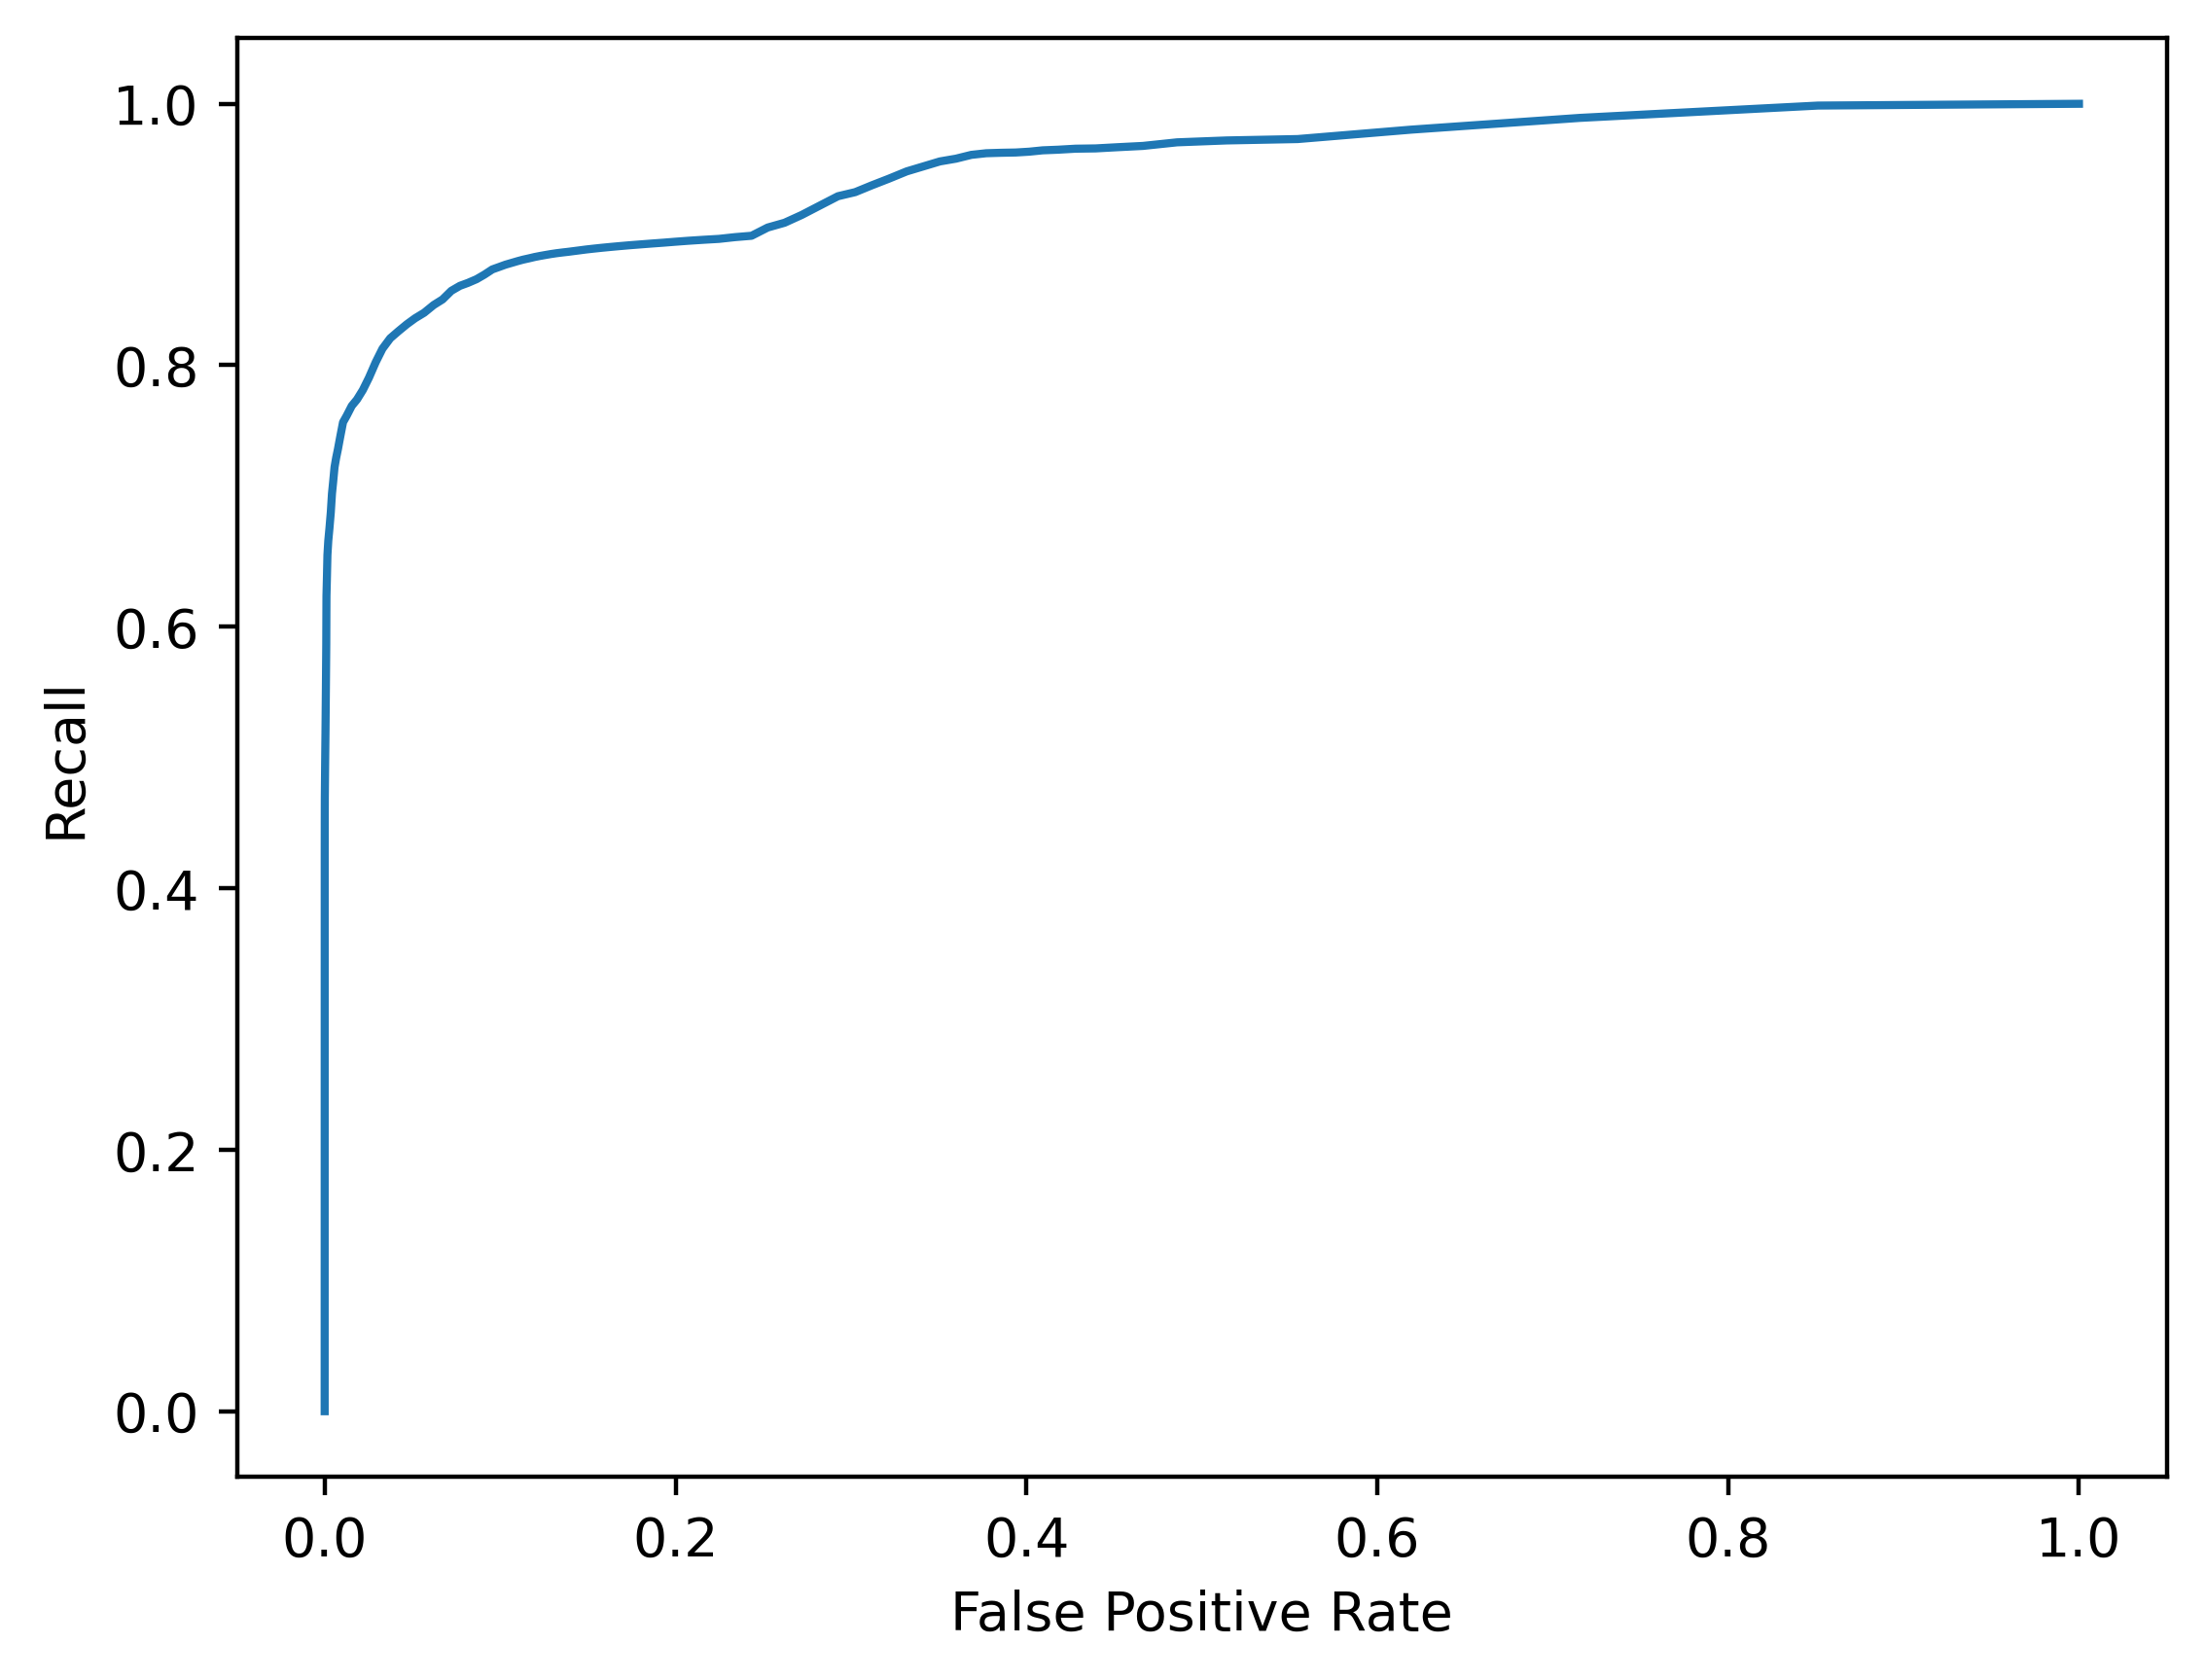

In [ ]:
plt.figure(dpi=400)
fpr, tpr, _ = metrics.roc_curve(test_y,  preds_proba[:,1])
plt.plot(fpr,tpr)
plt.ylabel('Recall')
plt.xlabel('False Positive Rate')
plt.show()

In [ ]:
pr = sklearn.metrics.precision_score(test_y, preds)
rec = sklearn.metrics.recall_score(test_y, preds)
print(pr, rec)

0.9656250444243317 0.8843728944858721


In [ ]:
precision, recall, thr = metrics.precision_recall_curve(test_y,  preds_proba[:,1])

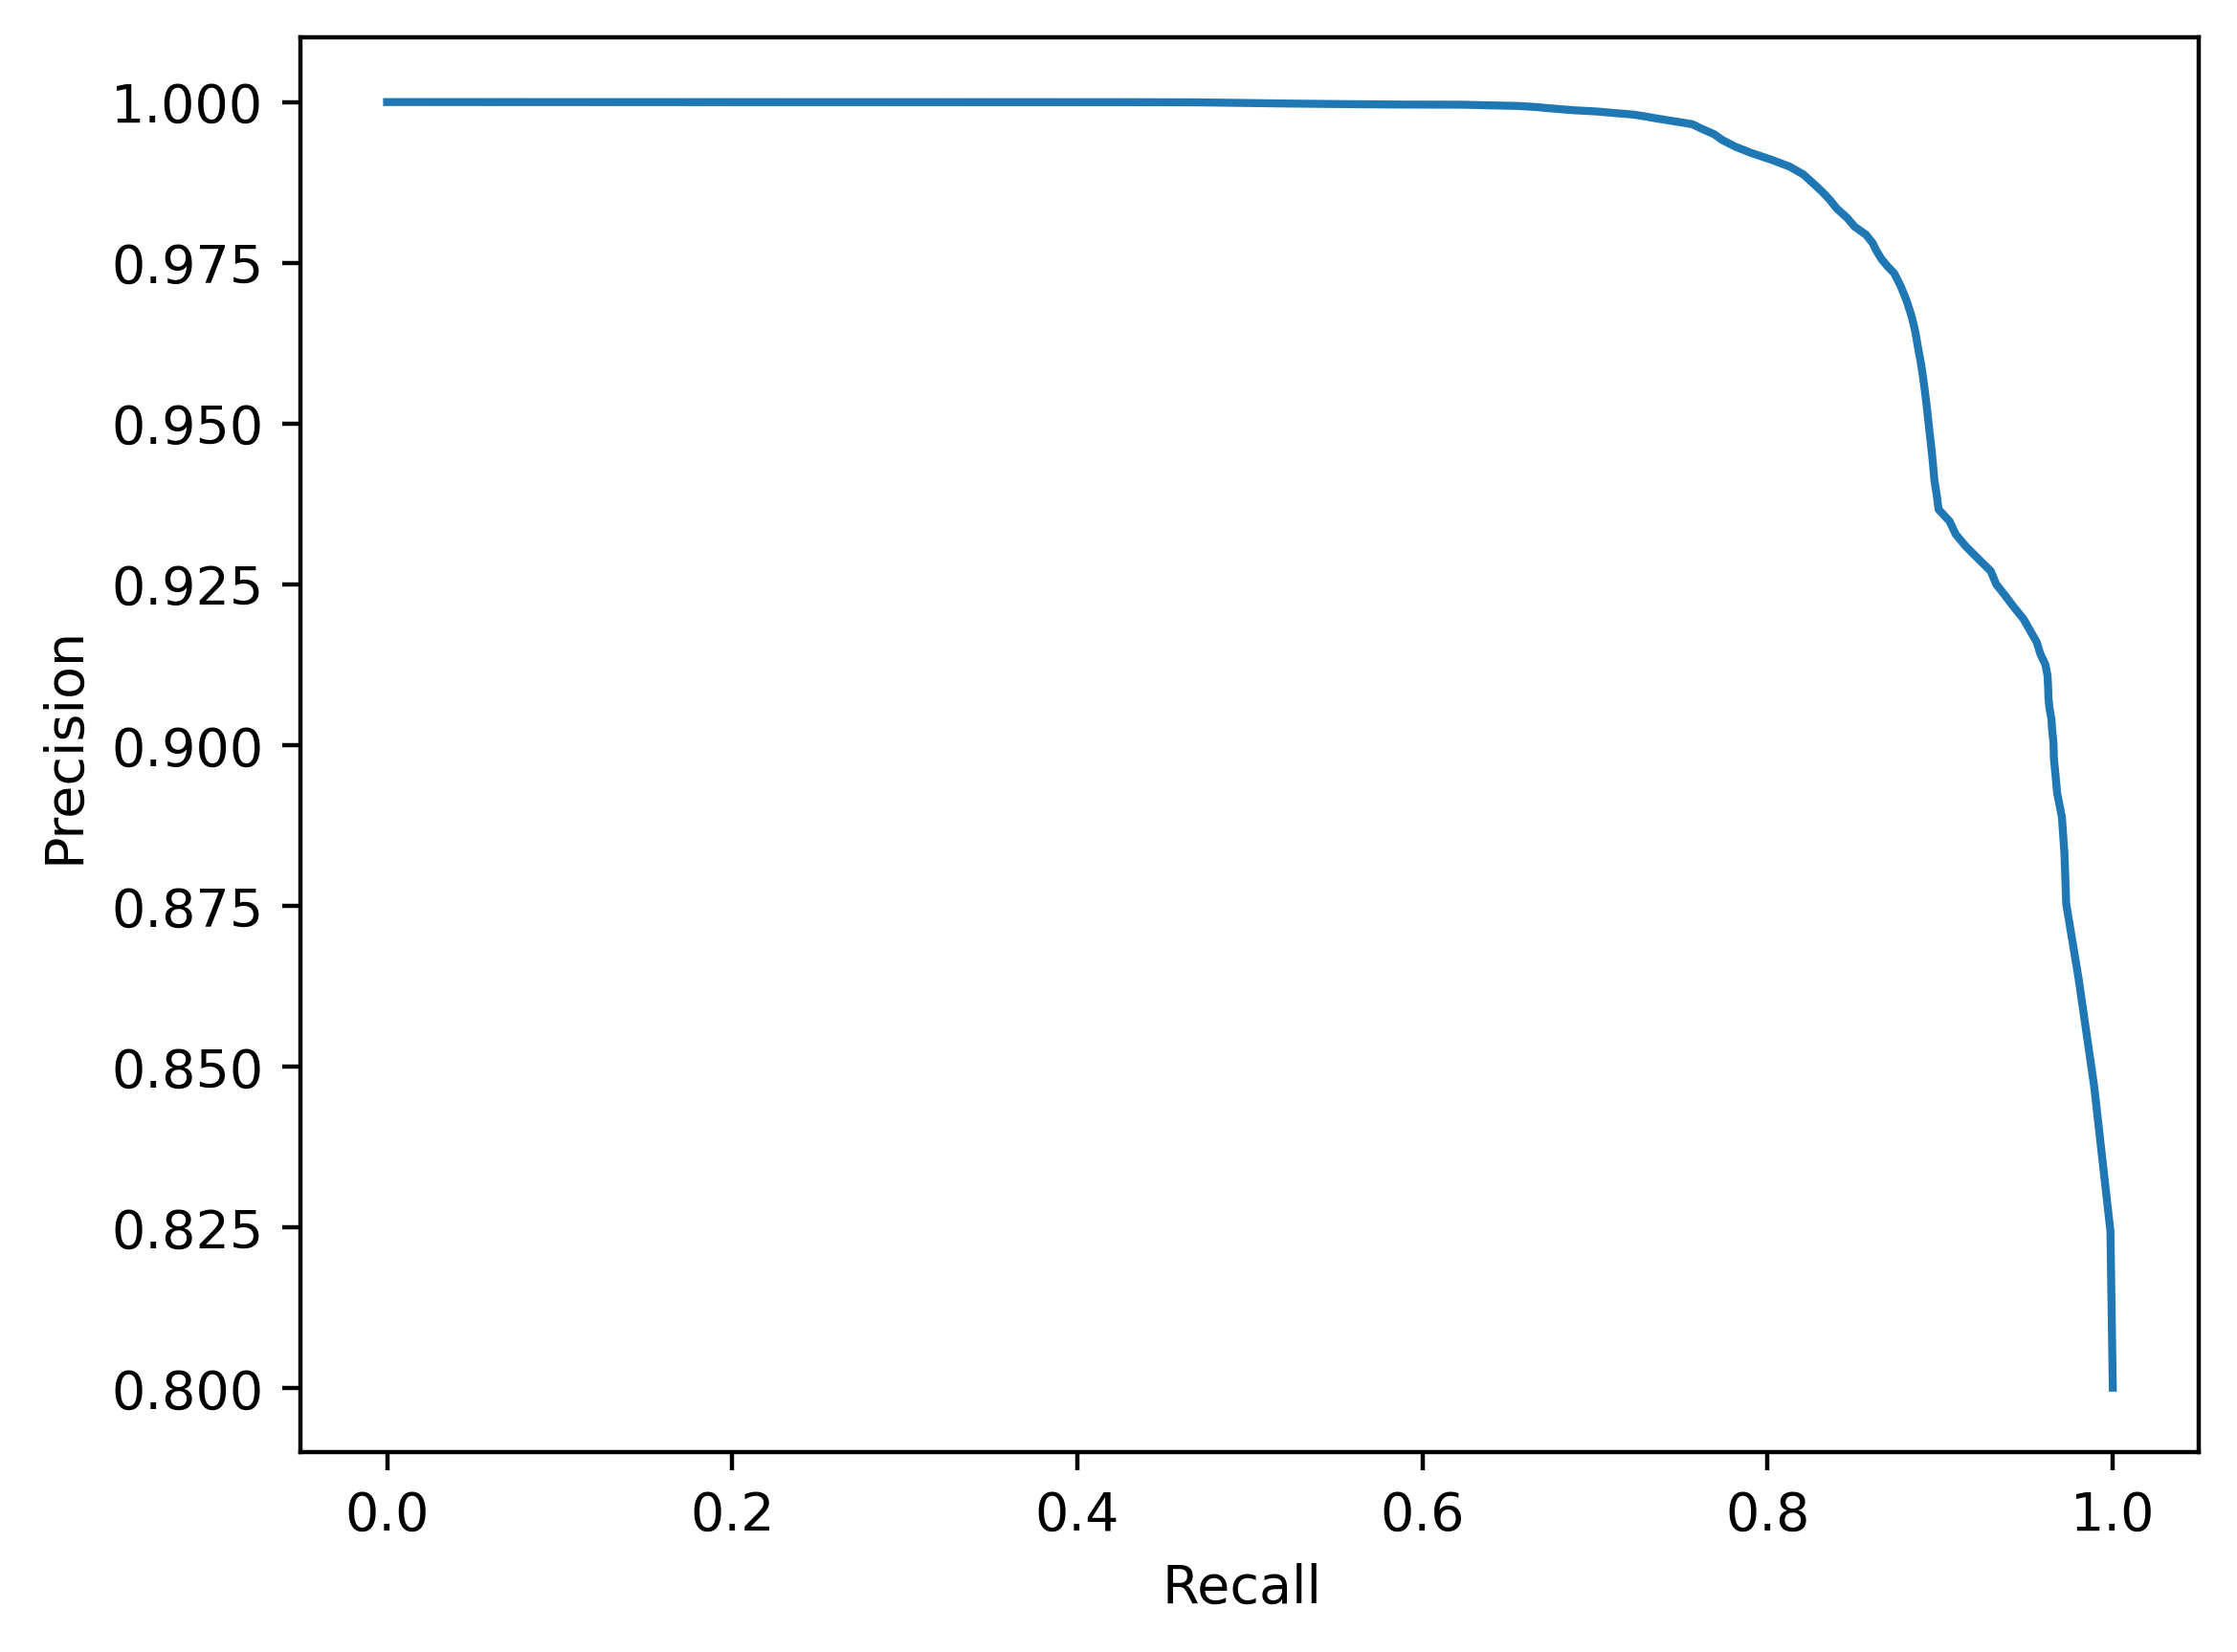

In [ ]:
plt.figure(dpi=400)
plt.plot(recall, precision)
plt.ylabel('Precision')
plt.xlabel('Recall ')
plt.show()

## Loop FPR Evaluation
Instead of recomputing the results, you can also load the ones we compute for the paper. To do so skip this section or name differently the path variable in the final cell.

In [ ]:
import sklearn
from sklearn import metrics
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

In [ ]:
timestamp = pd.to_datetime(timestamp, unit='ms')

In [ ]:
fpr, tpr, thresholds = metrics.roc_curve(test_y, preds_proba[:,1])

In [ ]:
desired_fpr = [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2]

In [ ]:
fpr_indexes = []
for val in desired_fpr:
    index = np.argmax(fpr > val)
    fpr_indexes.append(index)

In [ ]:
fpr_thresholds = thresholds[fpr_indexes]

In [ ]:
bin_preds_fpr = []
for val in fpr_thresholds:
    bin_pred = (preds_proba[:, 1] > val).astype(int)
    bin_preds_fpr.append(bin_pred)

In [ ]:
bin_preds_fpr

[array([0, 0, 0, ..., 0, 0, 0]),
 array([0, 0, 0, ..., 0, 0, 0]),
 array([0, 0, 0, ..., 0, 0, 0]),
 array([0, 0, 0, ..., 0, 0, 0]),
 array([0, 0, 0, ..., 0, 0, 0]),
 array([0, 0, 0, ..., 1, 1, 1]),
 array([0, 0, 0, ..., 1, 1, 1]),
 array([1, 1, 0, ..., 1, 1, 1])]

The path variable has to be adjusted to point to a dedicated folder for the model

In [ ]:
from dateutil.parser import parse

for val, des_fpr in zip(bin_preds_fpr, desired_fpr):
    bin_pred = val

    df_out = pd.DataFrame(columns=['start_idx_attack', 'end_idx_attack', 'attack_duration', 'time_to_detect', 'idx_detection_abs', 'idx_detection_rel', 'attack_len', 'attack_type','fpr','tpr','pr','rec','tn', 'fp','fn','tp','target_fpr'])
    last = 0
    i = 0
    for seq in test_set_lists:
        seq_x = X[seq]
        seq_y = Y[seq]
        seq_preds = bin_pred[last: last + seq_y.shape[0]]
        seq_preds = np.array(seq_preds)

        seq_check = test_y[last: last + seq_y.shape[0]]
        y_test_atk= np.where(Y[seq] == 1)[0]
        y_test_norm= np.where(Y[seq] ==  0)[0]

        conf_matrix = sklearn.metrics.confusion_matrix(seq_y, seq_preds)
        tn, fp, fn, tp = conf_matrix.ravel()
        fpr = fp / (tp + fp)
        tpr = tp / (tp + fn)

        pr = sklearn.metrics.precision_score(seq_y, seq_preds)
        rec = sklearn.metrics.recall_score(seq_y, seq_preds)

        preds_1=seq_preds[y_test_atk]

        date_time_0 = timestamp[seq[y_test_atk[0]]]
        date_time_last = timestamp[seq[y_test_atk[len(y_test_atk)-1]]]
        attack_time = date_time_last - date_time_0

        if 1 in seq_preds[y_test_atk]:
            index_rel = np.where(seq_preds[y_test_atk] == 1)[0][0]
            index = seq[y_test_atk[index_rel]]

            date_time_index = timestamp[index]
            detection_time = date_time_index - date_time_0
        else:
            index_rel = -1
            index = -1
            detection_time = -1

        df_out.loc[i] = pd.Series({'start_idx_attack': seq[y_test_atk[0]], 'end_idx_attack': seq[y_test_atk[len(y_test_atk)-1]],
                               'attack_duration': attack_time , 'time_to_detect': detection_time, 'idx_detection_abs': index,
                               'idx_detection_rel':index_rel, 'attack_len': y_test_atk.shape[0],
                               'attack_type':multi_err_label[seq[y_test_atk[0]]],'fpr':fpr,'tpr': tpr, 'pr': pr, 'rec': rec,
                               'tn':tn, 'fp':fp, 'fn':fn, 'tp':tp, 'target_fpr':des_fpr})
        last = last+len(seq_y)
        i = i+1

    path = '../data/models/space/new_features/extra/' + time_bin + '/' + str(des_fpr) + '.csv'
    df_out.to_csv(path, index=None)

/tmp/ipykernel_6675/2745491648.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/2745491648.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_6675/2745491648.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp 

/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = 

/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification

/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification

/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = 

/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = 

... (34 outputs left out)

/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification

/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = 

/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = 

/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = fp / (tp + fp)
/home/puccetti/Downloads/yes/envs/space_paper/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_31595/3272274092.py:21: RuntimeWarning: invalid value encountered in scalar divide
  fpr = 

In [ ]:
root = '../data/models/space/new_features/extra/' + time_bin + '/'

In [ ]:
files = os.listdir(root)
csv_files = [file for file in files if file.endswith('.csv')]

In [ ]:
csv_files

['0.1.csv',
 '0.0001.csv',
 '0.001.csv',
 '0.01.csv',
 '0.05.csv',
 '0.2.csv',
 '0.005.csv',
 '0.0005.csv']

In [ ]:
for csv in csv_files:

    path = root + csv
    df = pd.read_csv(path)
    df['detected'] = df['idx_detection_abs'].apply(lambda x: 0 if x == -1 else 1)
    df.loc[df['detected'] == 0, 'idx_detection_rel'] = df['attack_len'] - 1
    df.loc[df['detected'] == 0, 'time_to_detect'] = df['attack_duration']
    df.loc[df['detected'] == 0, 'idx_detection_abs'] = df['end_idx_attack']
    df.to_csv(path[0:len(path)-4] + '_new.csv' , index=None)